# Assignment 9 – Image Classification using Pretrained Vision Transformer and CNN





In [ ]:
# Install KerasHub only if it is missing or too old (ViT support needs >= 0.21).
import importlib.util, importlib.metadata, subprocess, sys
from packaging.version import Version

def _needs_install(pkg="keras_hub", dist="keras-hub", minimum="0.21.0"):
    if importlib.util.find_spec(pkg) is None:
        return True
    return Version(importlib.metadata.version(dist)) < Version(minimum)

if _needs_install():
    print("Installing keras-hub ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "keras-hub"])
else:
    print("keras-hub already available:", importlib.metadata.version("keras-hub"))

keras-hub already available: 0.26.0


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # must be set BEFORE importing keras: we want the TensorFlow backend

import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers
import keras_hub                              # pretrained Vision Transformer lives here

from sklearn.metrics import classification_report, confusion_matrix, f1_score
from IPython.display import display, Markdown

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__, "| backend:", keras.backend.backend())
print("KerasHub   :", keras_hub.__version__)

TensorFlow : 2.20.0
Keras      : 3.13.2 | backend: tensorflow
KerasHub   : 0.26.0


In [ ]:
gpus = tf.config.list_physical_devices("GPU")
GPU_AVAILABLE = len(gpus) > 0

print("TensorFlow version :", tf.__version__)
print("GPU devices found  :", gpus)

if GPU_AVAILABLE:
    for g in gpus:
        details = tf.config.experimental.get_device_details(g)
        print(f"  -> {g.name} | {details.get('device_name', 'unknown GPU')} | compute capability {details.get('compute_capability')}")
    print("\n✅ GPU acceleration is AVAILABLE. Training will run on the GPU.")
    subprocess.run(["nvidia-smi"])               # shows GPU model and memory
else:
    print("\n⚠️ WARNING: No GPU detected. The notebook will still run on CPU, but it will be very slow.")
    print("   Use Runtime -> Change runtime type -> GPU (a ViT subset is used automatically on CPU).")

TensorFlow version : 2.20.0
GPU devices found  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
  -> /physical_device:GPU:0 | Tesla T4 | compute capability (7, 5)

✅ GPU acceleration is AVAILABLE. Training will run on the GPU.


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)   # also seeds Python, NumPy and the backend in one call

NUM_CLASSES = 10
VAL_SIZE    = 5000                  # 5,000 training images are held out for validation

# ---- CNN settings (trained from scratch on 32x32 images) ----
CNN_BATCH  = 128
CNN_EPOCHS = 20                     # EarlyStopping can stop earlier

# ---- ViT settings ----
VIT_PRESET            = "vit_base_patch16_224_imagenet"   # KerasHub preset name
VIT_IMG_SIZE          = 224         # input resolution this ViT was pretrained with
VIT_BATCH             = 64
VIT_STAGE1_EPOCHS     = 2           # feature extraction (frozen backbone)
VIT_STAGE2_EPOCHS     = 3           # fine-tuning of upper transformer blocks
VIT_UNFREEZE_BLOCKS   = 4           # number of top transformer blocks (out of 12) unfrozen in stage 2
VIT_TRAIN_LIMIT       = None if GPU_AVAILABLE else 5000   # on CPU only, use a small subset so the notebook finishes

print(f"Seed = {SEED} | CNN epochs <= {CNN_EPOCHS} | ViT epochs = {VIT_STAGE1_EPOCHS} (frozen) + {VIT_STAGE2_EPOCHS} (fine-tune)")
if VIT_TRAIN_LIMIT:
    print(f"CPU mode: ViT will use only {VIT_TRAIN_LIMIT} training images.")

Seed = 42 | CNN epochs <= 20 | ViT epochs = 2 (frozen) + 3 (fine-tune)


In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train_full = y_train_full.flatten()   # (N,1) -> (N,)
y_test       = y_test.flatten()

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("Training set :", x_train_full.shape, y_train_full.shape, x_train_full.dtype)
print("Test set     :", x_test.shape, y_test.shape)
print("Number of classes:", len(class_names))
print("Class names  :", class_names)
assert x_train_full.shape == (50000, 32, 32, 3) and x_test.shape == (10000, 32, 32, 3)

# Split off a validation set (used to monitor overfitting and to drive the callbacks).
# The TEST set is never used for model selection.
perm = np.random.default_rng(SEED).permutation(len(x_train_full))
val_idx, tr_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]
x_train, y_train = x_train_full[tr_idx], y_train_full[tr_idx]
x_val,   y_val   = x_train_full[val_idx], y_train_full[val_idx]
print(f"\nAfter split -> train: {x_train.shape[0]}, validation: {x_val.shape[0]}, test: {x_test.shape[0]}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 27s 0us/step
Training set : (50000, 32, 32, 3) (50000,) uint8
Test set     : (10000, 32, 32, 3) (10000,)
Number of classes: 10
Class names  : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

After split -> train: 45000, validation: 5000, test: 10000


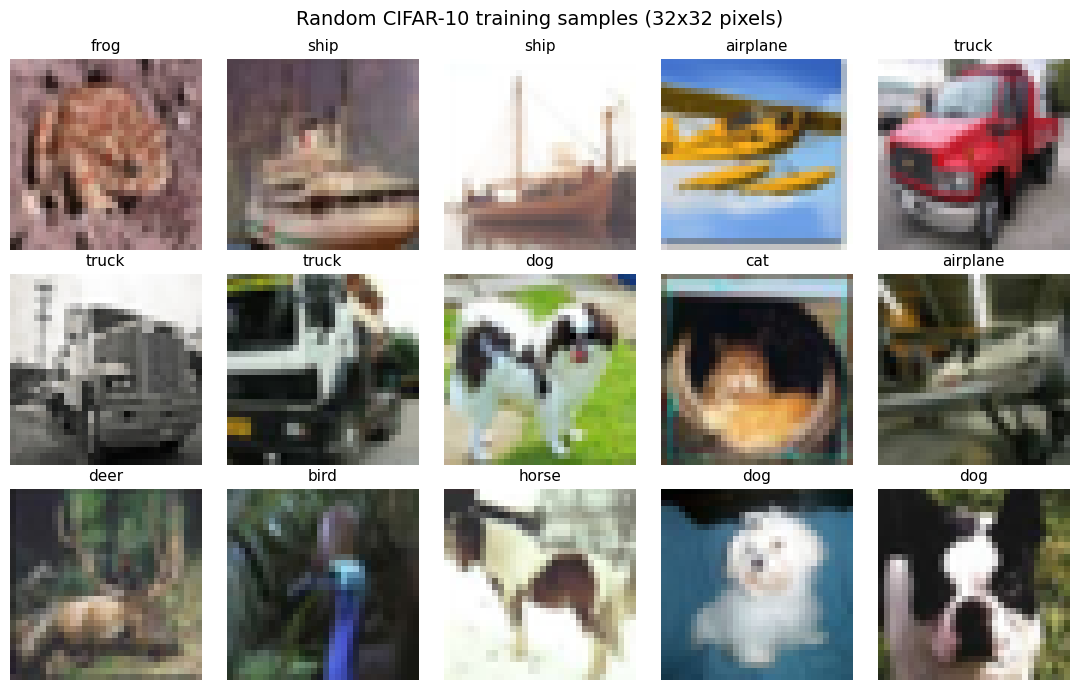

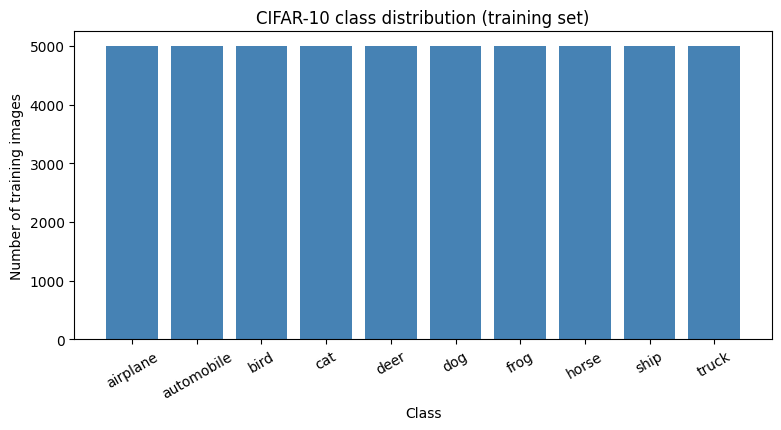

{'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


In [ ]:
# Grid of 15 random training images with their class names
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(x_train), 15, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for ax, i in zip(axes.ravel(), sample_idx):
    ax.imshow(x_train[i])
    ax.set_title(class_names[y_train[i]], fontsize=11)
    ax.axis("off")
plt.suptitle("Random CIFAR-10 training samples (32x32 pixels)", fontsize=14)
plt.tight_layout()
plt.show()

# Class distribution of the full training set
counts = np.bincount(y_train_full, minlength=NUM_CLASSES)
plt.figure(figsize=(9, 4))
plt.bar(class_names, counts, color="steelblue")
plt.ylabel("Number of training images")
plt.xlabel("Class")
plt.title("CIFAR-10 class distribution (training set)")
plt.xticks(rotation=30)
plt.show()
print(dict(zip(class_names, counts.tolist())))

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(x, y, batch_size, training):
    # Build an efficient tf.data pipeline from in-memory arrays.
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        # Full-size shuffle buffer so every epoch sees a different order (important for SGD-style training)
        ds = ds.shuffle(buffer_size=len(x), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    # uint8 -> float32 (values stay 0..255; each model rescales them itself)
    ds = ds.map(lambda img, lbl: (tf.cast(img, tf.float32), lbl), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)         # overlap data preparation with GPU computation

# CNN datasets
cnn_train_ds = make_dataset(x_train, y_train, CNN_BATCH, training=True)
cnn_val_ds   = make_dataset(x_val,   y_val,   CNN_BATCH, training=False)
cnn_test_ds  = make_dataset(x_test,  y_test,  CNN_BATCH, training=False)

# ViT datasets (smaller batch because 224x224 activations use much more GPU memory)
x_vit_train, y_vit_train = (x_train, y_train) if VIT_TRAIN_LIMIT is None else (x_train[:VIT_TRAIN_LIMIT], y_train[:VIT_TRAIN_LIMIT])
vit_train_ds = make_dataset(x_vit_train, y_vit_train, VIT_BATCH, training=True)
vit_val_ds   = make_dataset(x_val,  y_val,  128, training=False)
vit_test_ds  = make_dataset(x_test, y_test, 128, training=False)

xb, yb = next(iter(cnn_train_ds))
print("One CNN batch:", xb.shape, xb.dtype, "| labels:", yb.shape, yb.dtype)

One CNN batch: (128, 32, 32, 3) <dtype: 'float32'> | labels: (128,) <dtype: 'uint8'>


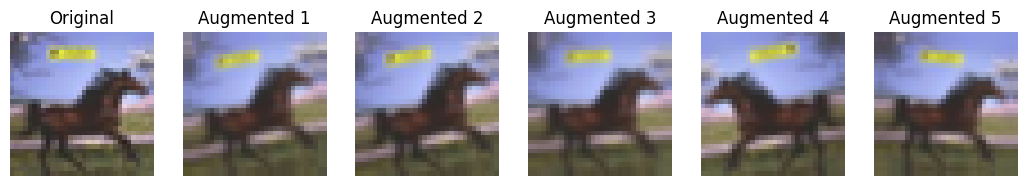

In [ ]:
def build_augmentation(name):
    # dtype="float32" keeps these layers in full precision even when mixed precision is enabled later.
    return keras.Sequential([
        layers.RandomFlip("horizontal", dtype="float32"),   # a flipped cat is still a cat (vertical flips are not natural)
        layers.RandomRotation(0.03, dtype="float32"),       # about +/- 11 degrees
        layers.RandomZoom(0.1, dtype="float32"),            # zoom in/out by up to 10%
    ], name=name)

# Visualise: one image augmented 5 times (training=True switches the random behaviour ON)
demo_aug = build_augmentation("demo_aug")
img = x_train[0:1].astype("float32")
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
axes[0].imshow(x_train[0]); axes[0].set_title("Original")
for k in range(1, 6):
    axes[k].imshow(np.clip(demo_aug(img, training=True)[0].numpy(), 0, 255).astype("uint8"))
    axes[k].set_title(f"Augmented {k}")
for a in axes: a.axis("off")
plt.show()

In [ ]:
def conv_block(x, filters, drop_rate):
    # Two 3x3 convolutions -> BatchNorm -> ReLU, then downsample and regularise.
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)  # bias is redundant before BatchNorm
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)          # halves height and width
    return layers.Dropout(drop_rate)(x)

def build_cnn():
    inputs = keras.Input(shape=(32, 32, 3), name="cifar_image")
    x = build_augmentation("cnn_augmentation")(inputs)   # active only while training
    x = layers.Rescaling(1.0 / 255, name="rescale_0_1")(x)
    x = conv_block(x, 32, 0.2)
    x = conv_block(x, 64, 0.3)
    x = conv_block(x, 128, 0.4)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="cnn_cifar10")

keras.backend.clear_session()
cnn_model = build_cnn()
cnn_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
cnn_model.summary()
cnn_params = cnn_model.count_params()
print(f"\nCNN total parameters: {cnn_params:,}")

Model: "cnn_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cifar_image (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_augmentation (Sequential)   │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 323,946 (1.24 MB)

 Trainable params: 323,050 (1.23 MB)

 Non-trainable params: 896 (3.50 KB)


CNN total parameters: 323,946


In [ ]:
cnn_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]

print(f"Training CNN for up to {CNN_EPOCHS} epochs ...")
t0 = time.time()
cnn_history = cnn_model.fit(cnn_train_ds, validation_data=cnn_val_ds,
                            epochs=CNN_EPOCHS, callbacks=cnn_callbacks, verbose=2)
cnn_train_time = time.time() - t0

cnn_hist = cnn_history.history
cnn_epochs_run = len(cnn_hist["loss"])
print(f"\nEpochs actually run     : {cnn_epochs_run}")
print(f"Training time           : {cnn_train_time:.1f} s ({cnn_train_time/60:.2f} min)")
print(f"Final training accuracy : {cnn_hist['accuracy'][-1]:.4f}")
print(f"Final validation acc.   : {cnn_hist['val_accuracy'][-1]:.4f}")
print(f"Best validation acc.    : {max(cnn_hist['val_accuracy']):.4f}")

Training CNN for up to 20 epochs ...
Epoch 1/20
352/352 - 20s - 57ms/step - accuracy: 0.4222 - loss: 1.5590 - val_accuracy: 0.1932 - val_loss: 2.9920 - learning_rate: 0.0010
Epoch 2/20
352/352 - 10s - 29ms/step - accuracy: 0.5657 - loss: 1.2051 - val_accuracy: 0.5806 - val_loss: 1.1530 - learning_rate: 0.0010
Epoch 3/20
352/352 - 10s - 29ms/step - accuracy: 0.6191 - loss: 1.0710 - val_accuracy: 0.6038 - val_loss: 1.0936 - learning_rate: 0.0010
Epoch 4/20
352/352 - 10s - 30ms/step - accuracy: 0.6512 - loss: 0.9809 - val_accuracy: 0.5856 - val_loss: 1.2334 - learning_rate: 0.0010
Epoch 5/20

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
352/352 - 10s - 30ms/step - accuracy: 0.6780 - loss: 0.9145 - val_accuracy: 0.6328 - val_loss: 1.1085 - learning_rate: 0.0010
Epoch 6/20
352/352 - 10s - 30ms/step - accuracy: 0.7143 - loss: 0.8146 - val_accuracy: 0.6574 - val_loss: 1.0027 - learning_rate: 5.0000e-04
Epoch 7/20
352/352 - 11s - 30ms/step - accuracy: 0.7262 - lo

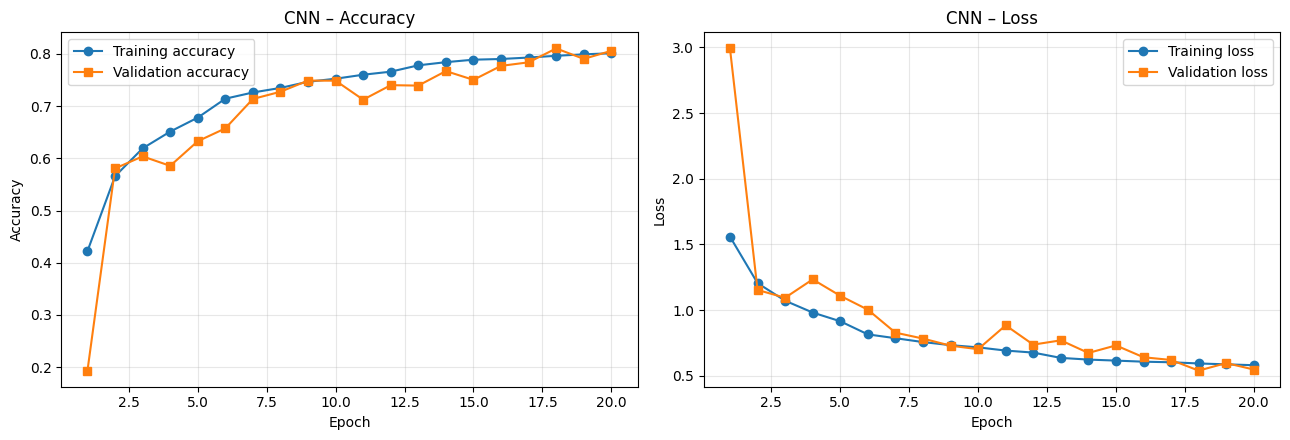

In [ ]:
def plot_history(hist, title, boundary=None):
    # hist: dict from Keras history. boundary: epoch index where fine-tuning starts (drawn as a dashed line).
    epochs = range(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, key, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(epochs, hist[key], "o-", label=f"Training {label.lower()}")
        ax.plot(epochs, hist["val_" + key], "s-", label=f"Validation {label.lower()}")
        if boundary:
            ax.axvline(boundary + 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
        ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_title(f"{title} – {label}")
        ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

plot_history(cnn_hist, "CNN")

In [ ]:
def evaluate_model(model, ds, y_true):
    # Returns test loss/accuracy, predictions, macro-F1 and the classification report string.
    loss, acc = model.evaluate(ds, verbose=0)
    probs  = model.predict(ds, verbose=0)
    y_pred = np.argmax(probs, axis=1)            # class with the highest softmax probability
    assert probs.shape == (len(y_true), NUM_CLASSES)
    return {
        "loss": float(loss), "accuracy": float(acc), "y_pred": y_pred,
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "report": classification_report(y_true, y_pred, target_names=class_names, digits=4),
    }

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
    thresh = cm.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > thresh else "black")
    ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class"); ax.set_title(title)
    fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

def show_predictions(images, y_true, y_pred, title, n=15, only_wrong=False):
    # Green title = correct prediction, red title = wrong prediction.
    pool = np.where(y_true != y_pred)[0] if only_wrong else np.arange(len(images))
    idx = np.random.default_rng(SEED).choice(pool, size=min(n, len(pool)), replace=False)
    fig, axes = plt.subplots(3, 5, figsize=(12, 8))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ok = y_true[i] == y_pred[i]
        ax.imshow(images[i])
        ax.set_title(f"Actual: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]}",
                     color="green" if ok else "red", fontsize=10)
    plt.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

cnn_res = evaluate_model(cnn_model, cnn_test_ds, y_test)
print(f"CNN Test loss     : {cnn_res['loss']:.4f}")
print(f"CNN Test accuracy : {cnn_res['accuracy']:.4f}  ({cnn_res['accuracy']*100:.2f}%)")
print(f"CNN Test macro-F1 : {cnn_res['macro_f1']:.4f}\n")
print("Classification report (CNN):\n")
print(cnn_res["report"])

CNN Test loss     : 0.5648
CNN Test accuracy : 0.8049  (80.49%)
CNN Test macro-F1 : 0.8032

Classification report (CNN):

              precision    recall  f1-score   support

    airplane     0.8266    0.8200    0.8233      1000
  automobile     0.9262    0.9030    0.9144      1000
        bird     0.7683    0.6830    0.7231      1000
         cat     0.6878    0.6190    0.6516      1000
        deer     0.7626    0.7870    0.7746      1000
         dog     0.7778    0.6720    0.7210      1000
        frog     0.7026    0.9120    0.7937      1000
       horse     0.8669    0.8340    0.8502      1000
        ship     0.8814    0.9070    0.8940      1000
       truck     0.8612    0.9120    0.8859      1000

    accuracy                         0.8049     10000
   macro avg     0.8061    0.8049    0.8032     10000
weighted avg     0.8061    0.8049    0.8032     10000



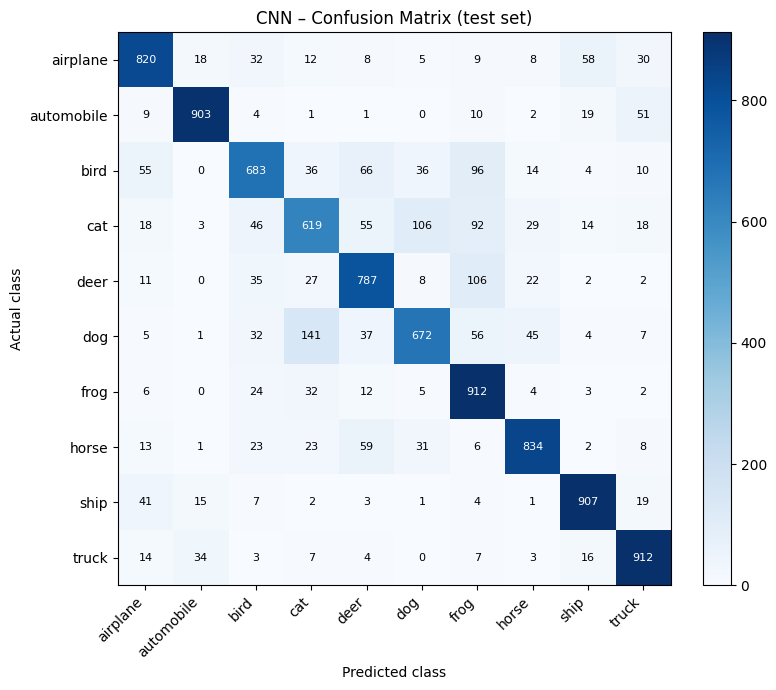

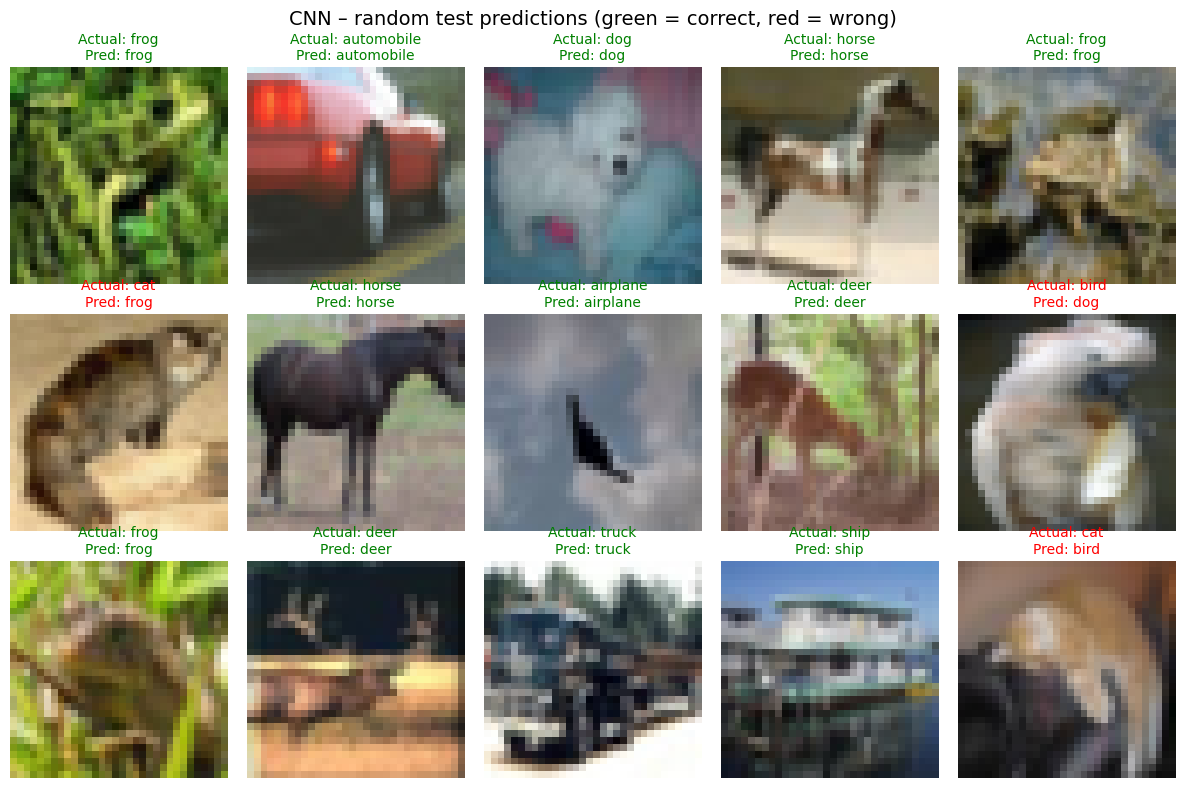

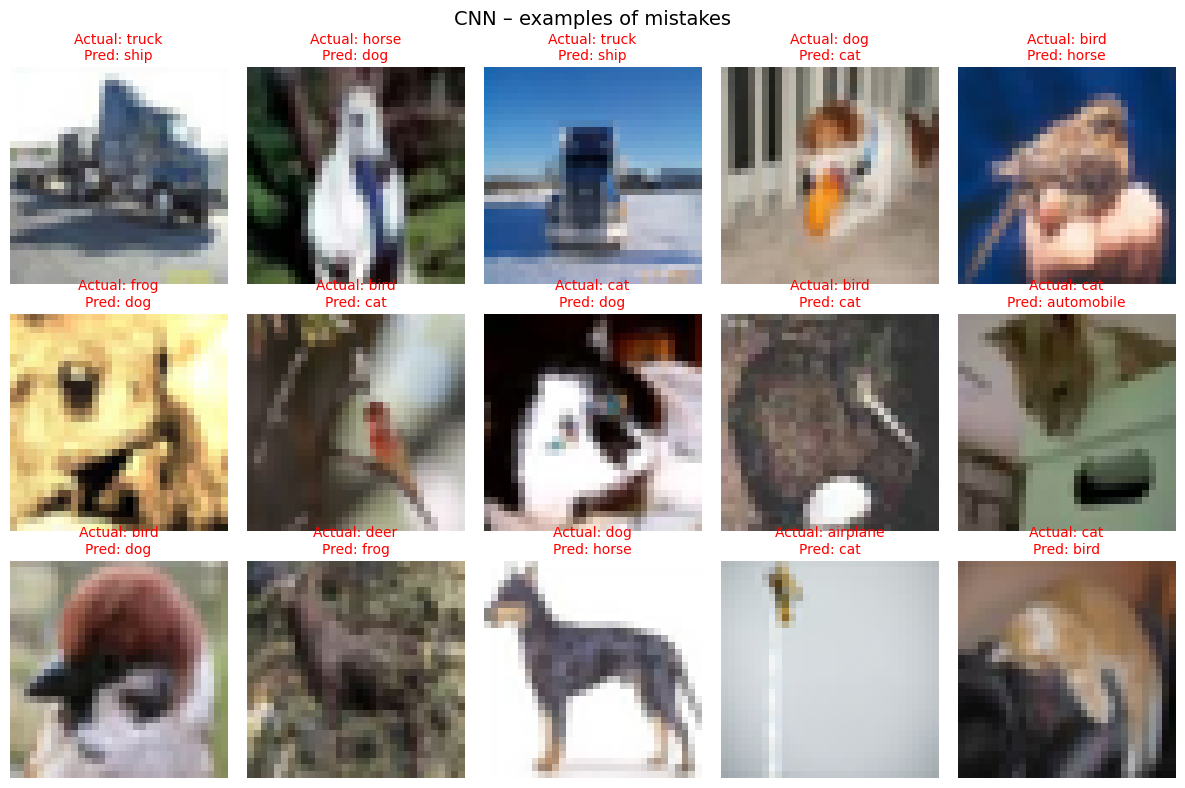

In [ ]:
plot_confusion_matrix(y_test, cnn_res["y_pred"], "CNN – Confusion Matrix (test set)")
show_predictions(x_test, y_test, cnn_res["y_pred"], "CNN – random test predictions (green = correct, red = wrong)")
show_predictions(x_test, y_test, cnn_res["y_pred"], "CNN – examples of mistakes", only_wrong=True)

In [ ]:
# Show what the preset is (description comes from KerasHub, so the notebook documents its own source)
preset_info = keras_hub.models.ViTBackbone.presets[VIT_PRESET]
print("Preset      :", VIT_PRESET)
print("Description :", preset_info.get("description", "n/a"))

# Read the exact normalisation (scale/offset) used by this preset's own image converter,
# so our preprocessing matches what the weights were trained with.
preproc = keras_hub.models.ViTImageClassifierPreprocessor.from_preset(VIT_PRESET)
vit_scale  = preproc.image_converter.scale
vit_offset = preproc.image_converter.offset
print("\nPreset input size :", preproc.image_converter.image_size)
print("Preset scale/offset:", vit_scale, vit_offset, "(pixel * scale + offset)")

Preset      : vit_base_patch16_224_imagenet
Description : n/a


100%|██████████| 698/698 [00:00<00:00, 1.58MB/s]


100%|██████████| 1.74k/1.74k [00:00<00:00, 4.20MB/s]



Preset input size : (224, 224)
Preset scale/offset: [0.00784313725490196, 0.00784313725490196, 0.00784313725490196] [-1.0, -1.0, -1.0] (pixel * scale + offset)


In [ ]:
if GPU_AVAILABLE:
    keras.mixed_precision.set_global_policy("mixed_float16")
print("Global dtype policy:", keras.mixed_precision.global_policy().name)

# Download pretrained weights (needs internet, ~330 MB). Weights are cached after the first call.
vit_backbone = keras_hub.models.ViTBackbone.from_preset(VIT_PRESET)
print("\nBackbone input shape :", vit_backbone.input_shape)
print("Backbone output shape:", vit_backbone.output_shape, "-> (batch, 1 [CLS] + 196 patches, 768)")
print(f"Backbone parameters  : {vit_backbone.count_params():,}")

Global dtype policy: mixed_float16


100%|██████████| 328M/328M [00:06<00:00, 53.4MB/s]



Backbone input shape : (None, 224, 224, 3)
Backbone output shape: (None, 197, 768) -> (batch, 1 [CLS] + 196 patches, 768)
Backbone parameters  : 85,798,656


In [ ]:
def build_vit_classifier(backbone):
    inputs = keras.Input(shape=(32, 32, 3), name="cifar_image")
    x = build_augmentation("vit_augmentation")(inputs)                        # mild augmentation at 32x32 (cheap)
    x = layers.Resizing(VIT_IMG_SIZE, VIT_IMG_SIZE, interpolation="bilinear",
                        dtype="float32", name="resize_to_224")(x)             # 32x32 -> 224x224 on the GPU
    x = layers.Rescaling(scale=vit_scale, offset=vit_offset,
                         dtype="float32", name="vit_normalise")(x)            # same normalisation as pretraining
    tokens = backbone(x)                                                      # (batch, 197, 768)
    cls_feature = tokens[:, 0]                                                # [CLS] token = image representation
    x = layers.Dropout(0.2)(cls_feature)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax",
                           dtype="float32", name="cifar10_head")(x)           # NEW 10-class head
    return keras.Model(inputs, outputs, name="vit_cifar10")

vit_model = build_vit_classifier(vit_backbone)
vit_model.summary()

vit_params = vit_model.count_params()
print(f"\nViT total parameters: {vit_params:,}")
print("Input  shape:", vit_model.input_shape, "| Output shape:", vit_model.output_shape)
assert vit_model.output_shape == (None, NUM_CLASSES)

Model: "vit_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cifar_image (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vit_augmentation (Sequential)   │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize_to_224 (Resizing)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vit_normalise (Rescaling)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vi_t_backbone (ViTBackbone)     │ (None, 197, 768)       │    85,798,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ get_item (GetItem)              │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cifar10_head (Dense)            │ (None, 10)             │         7,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,806,346 (327.33 MB)

 Trainable params: 85,806,346 (327.33 MB)

 Non-trainable params: 0 (0.00 B)


ViT total parameters: 85,806,346
Input  shape: (None, 32, 32, 3) | Output shape: (None, 10)


## 13. ViT Fine-Tuning Strategy

We use a **two-stage transfer-learning** approach. Fine-tuning the whole 86M-parameter model with a large learning rate would destroy the pretrained features ("catastrophic forgetting") and would be slow.

| Stage | What is trained | Learning rate | Epochs | Why |
|---|---|---|---|---|
| **1 – Feature extraction** | Only the new head (backbone frozen) | 1e-3 | 2 | The random head must first learn to read the pretrained features, otherwise its large random gradients would damage the backbone. |
| **2 – Fine-tuning** | Head + top 4 of 12 transformer blocks + final LayerNorm | 2e-5 (small) | 3 | Upper blocks hold more task-specific features; adapting them to CIFAR-10 improves accuracy. The small learning rate makes gentle changes. Lower blocks (generic edges/textures) stay frozen, which also saves time. |



In [ ]:
def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

# ---------------- Stage 1: feature extraction (backbone frozen) ----------------
vit_backbone.trainable = False
vit_model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"Stage 1 trainable parameters: {count_trainable(vit_model):,} of {vit_params:,} (only the new head)")

stage1_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
]
t0 = time.time()
vit_hist1 = vit_model.fit(vit_train_ds, validation_data=vit_val_ds,
                          epochs=VIT_STAGE1_EPOCHS, callbacks=stage1_callbacks, verbose=2)
vit_time_stage1 = time.time() - t0
print(f"\nStage 1 time: {vit_time_stage1:.1f} s | best val acc: {max(vit_hist1.history['val_accuracy']):.4f}")

Stage 1 trainable parameters: 7,690 of 85,806,346 (only the new head)
Epoch 1/2
704/704 - 359s - 510ms/step - accuracy: 0.8687 - loss: 0.4064 - val_accuracy: 0.9636 - val_loss: 0.1121 - learning_rate: 0.0010
Epoch 2/2
704/704 - 344s - 488ms/step - accuracy: 0.9056 - loss: 0.2824 - val_accuracy: 0.9674 - val_loss: 0.1015 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.

Stage 1 time: 703.0 s | best val acc: 0.9674


In [ ]:
# ---------------- Stage 2: fine-tune the upper transformer blocks ----------------
# Unfreeze everything first, then re-freeze the patch embedding and the lower blocks.
vit_backbone.trainable = True
vit_backbone.get_layer("vit_patching_and_embedding").trainable = False
encoder = vit_backbone.get_layer("vit_encoder")
n_blocks = len(encoder.encoder_layers)
for block in encoder.encoder_layers[: n_blocks - VIT_UNFREEZE_BLOCKS]:
    block.trainable = False

# IMPORTANT: the model must be re-compiled after changing 'trainable' so the change takes effect.
vit_model.compile(optimizer=keras.optimizers.Adam(2e-5, clipnorm=1.0),   # much smaller learning rate
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"Stage 2: {VIT_UNFREEZE_BLOCKS} of {n_blocks} transformer blocks unfrozen")
print(f"Stage 2 trainable parameters: {count_trainable(vit_model):,} of {vit_params:,}")

stage2_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6, verbose=1),
]
t0 = time.time()
vit_hist2 = vit_model.fit(vit_train_ds, validation_data=vit_val_ds,
                          epochs=VIT_STAGE2_EPOCHS, callbacks=stage2_callbacks, verbose=2)
vit_time_stage2 = time.time() - t0

vit_train_time = vit_time_stage1 + vit_time_stage2
vit_hist = {k: vit_hist1.history[k] + vit_hist2.history[k] for k in vit_hist1.history}   # merge both stages
vit_stage1_epochs_run = len(vit_hist1.history["loss"])
print(f"\nStage 2 time: {vit_time_stage2:.1f} s")
print(f"Total ViT training time : {vit_train_time:.1f} s ({vit_train_time/60:.2f} min)")
print(f"Final training accuracy : {vit_hist['accuracy'][-1]:.4f}")
print(f"Final validation acc.   : {vit_hist['val_accuracy'][-1]:.4f}")
print(f"Best validation acc.    : {max(vit_hist['val_accuracy']):.4f}")

Stage 2: 4 of 12 transformer blocks unfrozen
Stage 2 trainable parameters: 28,360,714 of 85,806,346
Epoch 1/3
704/704 - 571s - 812ms/step - accuracy: 0.9332 - loss: 0.2033 - val_accuracy: 0.9780 - val_loss: 0.0711 - learning_rate: 2.0000e-05
Epoch 2/3
704/704 - 548s - 779ms/step - accuracy: 0.9536 - loss: 0.1419 - val_accuracy: 0.9794 - val_loss: 0.0629 - learning_rate: 2.0000e-05
Epoch 3/3
704/704 - 548s - 778ms/step - accuracy: 0.9614 - loss: 0.1123 - val_accuracy: 0.9790 - val_loss: 0.0596 - learning_rate: 2.0000e-05
Restoring model weights from the end of the best epoch: 2.

Stage 2 time: 1667.9 s
Total ViT training time : 2370.9 s (39.51 min)
Final training accuracy : 0.9614
Final validation acc.   : 0.9790
Best validation acc.    : 0.9794


In [ ]:
plot_history(vit_hist, "Pretrained ViT", boundary=vit_stage1_epochs_run)

In [ ]:
vit_res = evaluate_model(vit_model, vit_test_ds, y_test)
print(f"ViT Test loss     : {vit_res['loss']:.4f}")
print(f"ViT Test accuracy : {vit_res['accuracy']:.4f}  ({vit_res['accuracy']*100:.2f}%)")
print(f"ViT Test macro-F1 : {vit_res['macro_f1']:.4f}\n")
print("Classification report (ViT):\n")
print(vit_res["report"])

ViT Test loss     : 0.0700
ViT Test accuracy : 0.9776  (97.76%)
ViT Test macro-F1 : 0.9776

Classification report (ViT):

              precision    recall  f1-score   support

    airplane     0.9859    0.9820    0.9840      1000
  automobile     0.9742    0.9830    0.9786      1000
        bird     0.9839    0.9790    0.9815      1000
         cat     0.9609    0.9350    0.9478      1000
        deer     0.9869    0.9790    0.9829      1000
         dog     0.9402    0.9740    0.9568      1000
        frog     0.9851    0.9910    0.9880      1000
       horse     0.9960    0.9860    0.9910      1000
        ship     0.9890    0.9900    0.9895      1000
       truck     0.9750    0.9770    0.9760      1000

    accuracy                         0.9776     10000
   macro avg     0.9777    0.9776    0.9776     10000
weighted avg     0.9777    0.9776    0.9776     10000



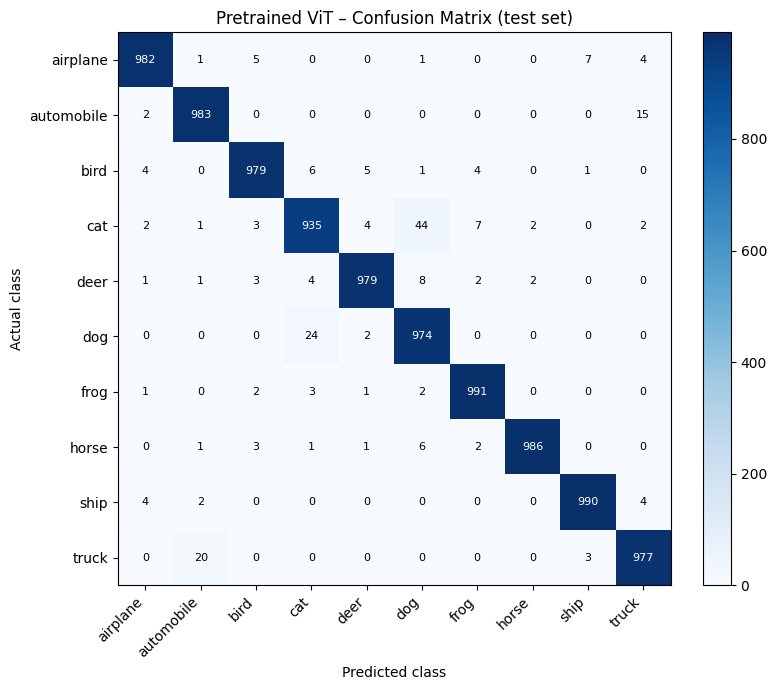

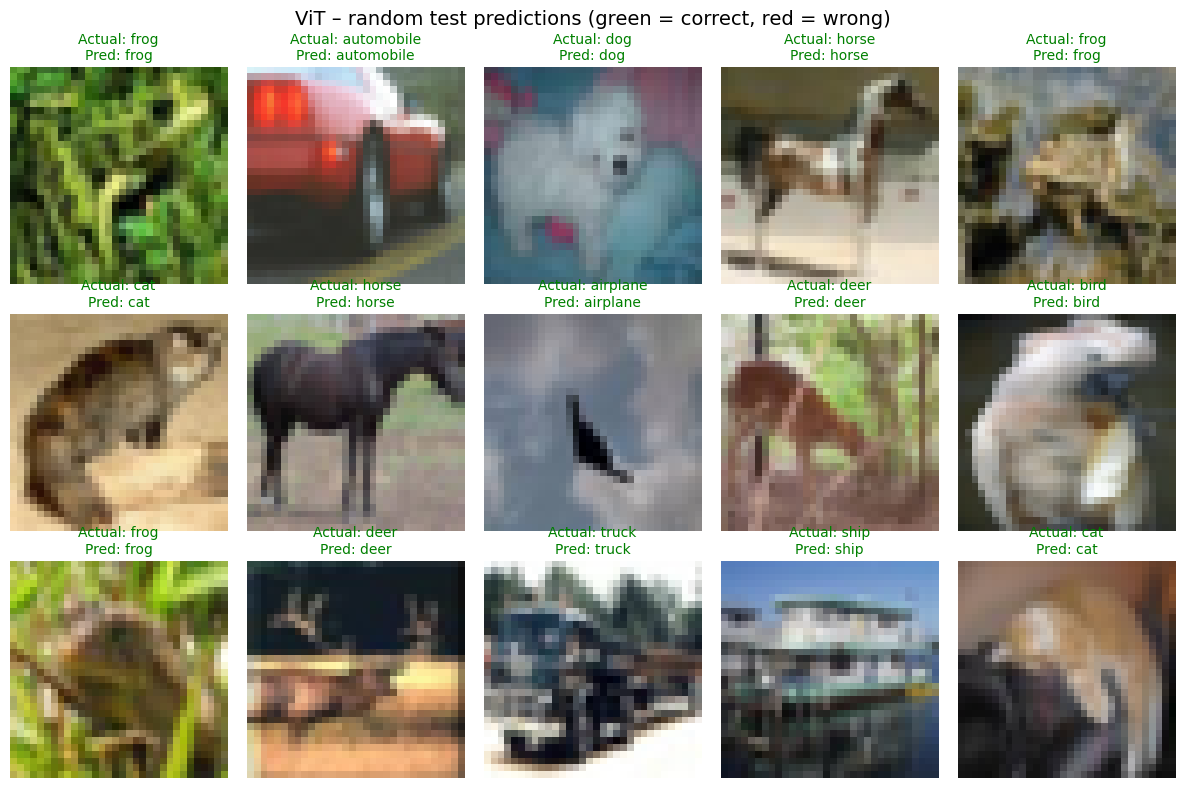

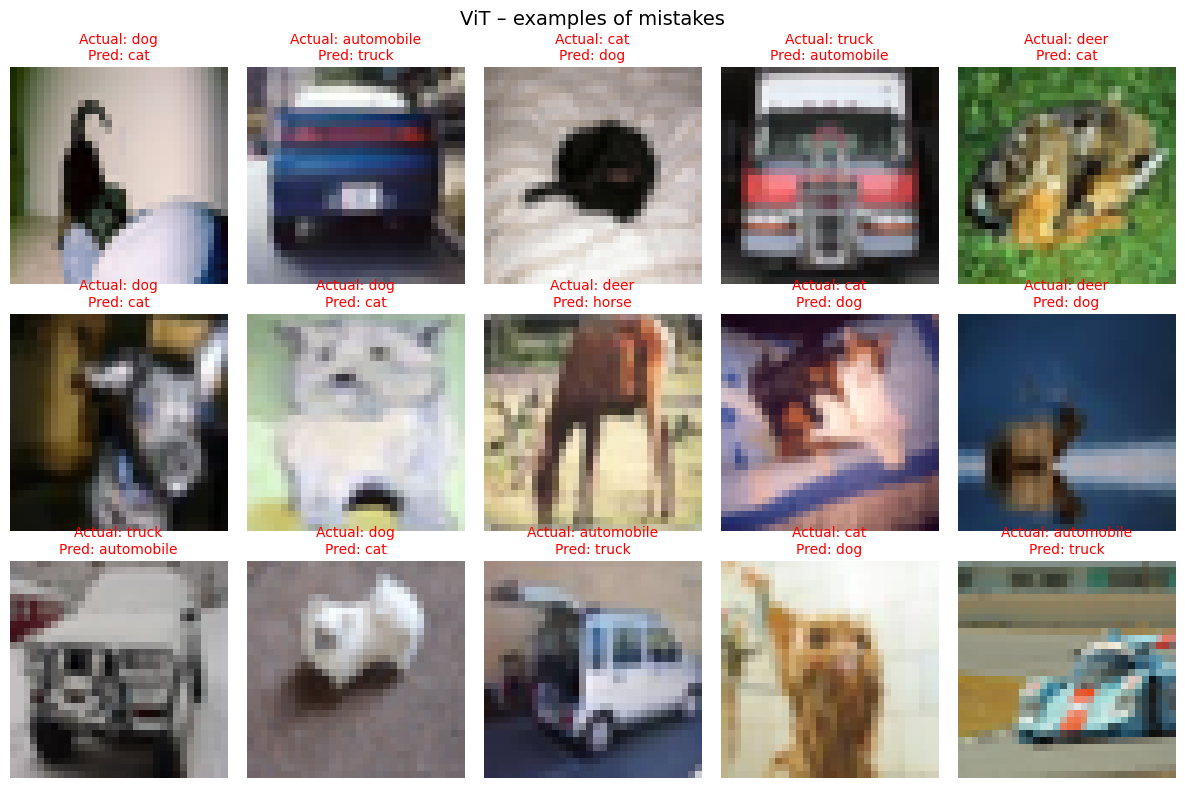

In [ ]:
plot_confusion_matrix(y_test, vit_res["y_pred"], "Pretrained ViT – Confusion Matrix (test set)")
show_predictions(x_test, y_test, vit_res["y_pred"], "ViT – random test predictions (green = correct, red = wrong)")
show_predictions(x_test, y_test, vit_res["y_pred"], "ViT – examples of mistakes", only_wrong=True)

In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Test Accuracy", "Test Loss", "Training Time (s)", "Training Time (min)",
               "Number of Parameters", "Best Validation Accuracy", "Test F1 Score (macro)",
               "Epochs Trained"],
    "CNN": [cnn_res["accuracy"], cnn_res["loss"], cnn_train_time, cnn_train_time / 60,
            cnn_params, max(cnn_hist["val_accuracy"]), cnn_res["macro_f1"], cnn_epochs_run],
    "Pretrained ViT": [vit_res["accuracy"], vit_res["loss"], vit_train_time, vit_train_time / 60,
                       vit_params, max(vit_hist["val_accuracy"]), vit_res["macro_f1"], len(vit_hist["loss"])],
}).set_index("Metric")

display(comparison.style.format({
    "CNN": lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.1f}" if abs(v) < 1e5 else f"{v:,.0f}",
    "Pretrained ViT": lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.1f}" if abs(v) < 1e5 else f"{v:,.0f}",
}))
comparison.to_csv("cnn_vs_vit_comparison.csv")
print("Table also saved to cnn_vs_vit_comparison.csv (Colab file browser, left sidebar).")

,CNN,Pretrained ViT
Metric,,
Test Accuracy,0.8049,0.9776
Test Loss,0.5648,0.0700
Training Time (s),221.2,"2,370.9"
Training Time (min),3.6868,39.5
Number of Parameters,"323,946","85,806,346"
Best Validation Accuracy,0.8106,0.9794
Test F1 Score (macro),0.8032,0.9776
Epochs Trained,20.0,5.0000


Table also saved to cnn_vs_vit_comparison.csv (Colab file browser, left sidebar).


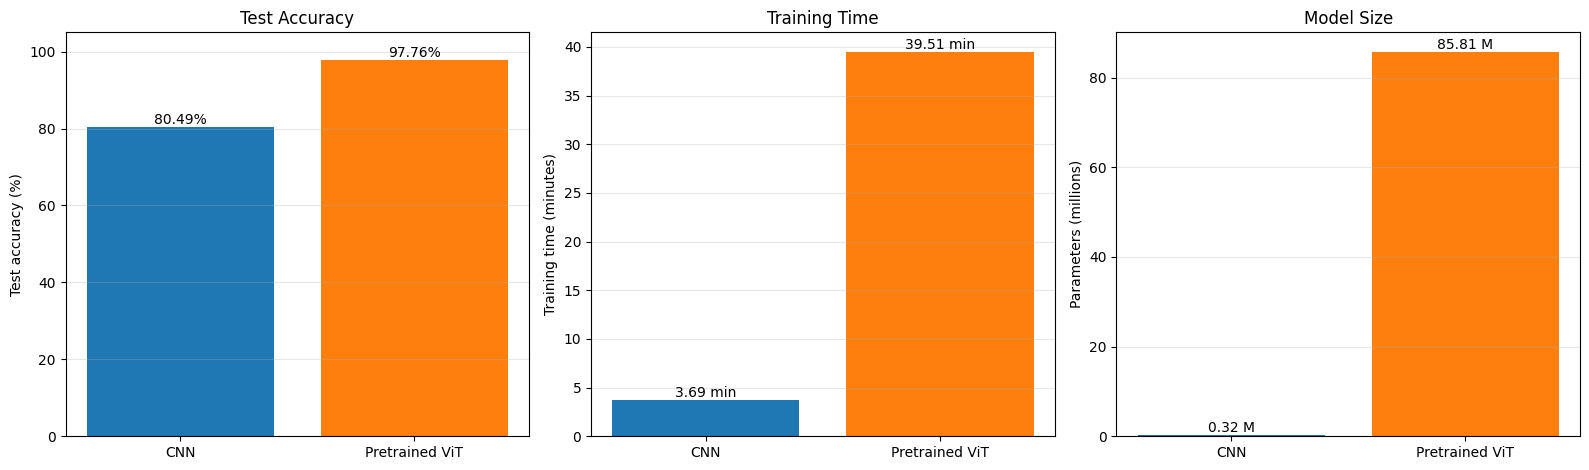

In [ ]:
labels = ["CNN", "Pretrained ViT"]
colors = ["tab:blue", "tab:orange"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Plot 1: Test accuracy
acc = [cnn_res["accuracy"] * 100, vit_res["accuracy"] * 100]
b = axes[0].bar(labels, acc, color=colors)
axes[0].set_ylabel("Test accuracy (%)"); axes[0].set_title("Test Accuracy")
axes[0].set_ylim(0, 105)
axes[0].bar_label(b, fmt="%.2f%%")

# Plot 2: Training time
tt = [cnn_train_time / 60, vit_train_time / 60]
b = axes[1].bar(labels, tt, color=colors)
axes[1].set_ylabel("Training time (minutes)"); axes[1].set_title("Training Time")
axes[1].bar_label(b, fmt="%.2f min")

# Plot 3 (optional): Parameter count
pp = [cnn_params / 1e6, vit_params / 1e6]
b = axes[2].bar(labels, pp, color=colors)
axes[2].set_ylabel("Parameters (millions)"); axes[2].set_title("Model Size")
axes[2].bar_label(b, fmt="%.2f M")

for ax in axes: ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()